<a href="https://colab.research.google.com/github/Najla-Nuricia/PemMes_244107020091_Najla/blob/main/JS07/JS07_tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Ukuran dataset:", df.shape)
display(df.head())
print(df.columns.tolist())

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset.csv
Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


['Sl_No', 'Customer Key', 'Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


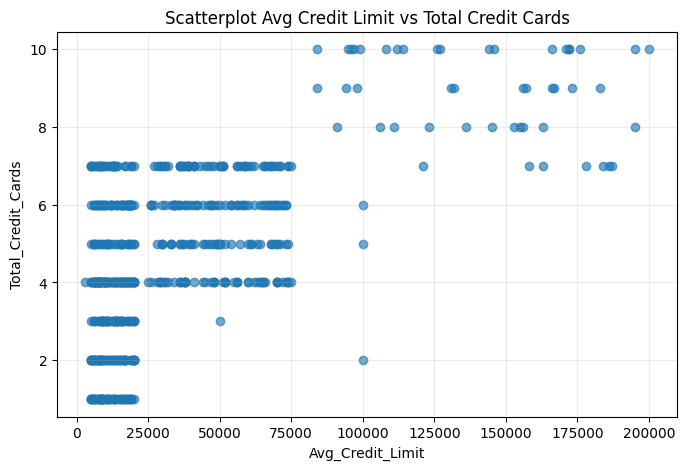

Korelasi Pearson: 0.6089


In [3]:
x_col = 'Avg_Credit_Limit'
y_col = 'Total_Credit_Cards'
data_2d = df[[x_col, y_col]].apply(pd.to_numeric, errors='coerce').dropna()

plt.figure(figsize=(8, 5))
plt.scatter(data_2d[x_col], data_2d[y_col], alpha=0.65)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title('Scatterplot Avg Credit Limit vs Total Credit Cards')
plt.grid(alpha=0.25)
plt.show()

corr = data_2d[x_col].corr(data_2d[y_col])
print(f'Korelasi Pearson: {corr:.4f}')

In [4]:
# Identifier tidak dipakai sebagai fitur clustering
feature_cols = [
    'Avg_Credit_Limit',
    'Total_Credit_Cards',
    'Total_visits_bank',
    'Total_visits_online',
    'Total_calls_made'
]
features = df[feature_cols].apply(pd.to_numeric, errors='coerce')
valid_idx = features.dropna().index
features = features.loc[valid_idx]
df_model = df.loc[valid_idx].copy()

# Standardisasi penting karena skala Avg_Credit_Limit jauh lebih besar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)
print('Jumlah data:', X_scaled.shape[0])
print('Fitur yang dipakai:', feature_cols)

Jumlah data: 660
Fitur yang dipakai: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


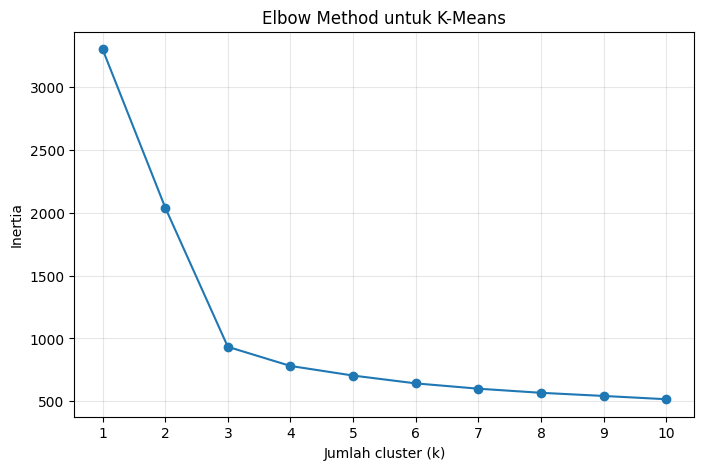

,k,Inertia
0,1,3300.000
1,2,2040.990
2,3,933.044
3,4,780.774
4,5,704.476
5,6,642.274
6,7,599.925
7,8,567.328
8,9,542.253
9,10,516.242


In [5]:
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker='o')
plt.xticks(list(k_values))
plt.xlabel('Jumlah cluster (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method untuk K-Means')
plt.grid(alpha=0.3)
plt.show()

display(pd.DataFrame({'k': list(k_values), 'Inertia': inertias}).round(3))

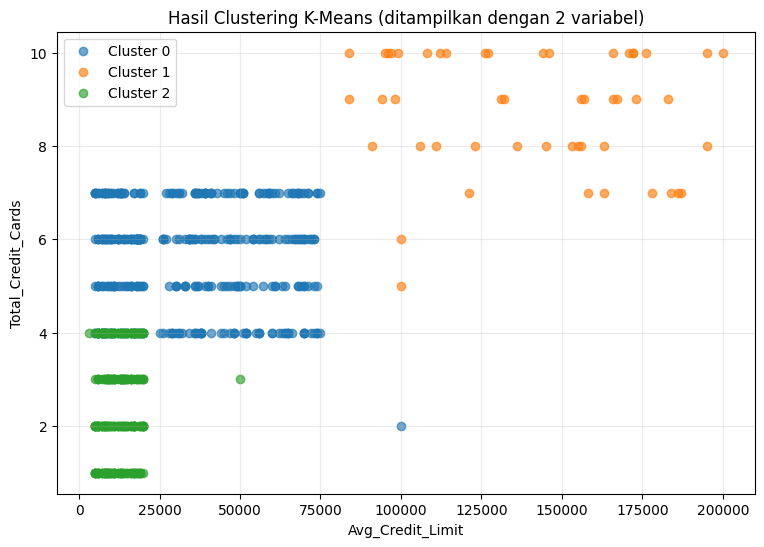

Jumlah anggota tiap cluster:


,Jumlah Data
KMeans_Cluster,
0,386
1,50
2,224


Rata-rata fitur per cluster:


,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
KMeans_Cluster,,,,,
0,33782.38,5.52,3.49,0.98,2.00
1,141040.00,8.74,0.60,10.90,1.08
2,12174.11,2.41,0.93,3.55,6.87


In [6]:
best_k = 3  # Berdasarkan grafik Elbow Method
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
df_model['KMeans_Cluster'] = kmeans_labels

plt.figure(figsize=(9, 6))
for cluster in sorted(df_model['KMeans_Cluster'].unique()):
    subset = df_model[df_model['KMeans_Cluster'] == cluster]
    plt.scatter(subset[x_col], subset[y_col], alpha=0.65, label=f'Cluster {cluster}')
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title('Hasil Clustering K-Means (ditampilkan dengan 2 variabel)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print('Jumlah anggota tiap cluster:')
display(df_model['KMeans_Cluster'].value_counts().sort_index().rename('Jumlah Data').to_frame())
print('Rata-rata fitur per cluster:')
display(df_model.groupby('KMeans_Cluster')[feature_cols].mean().round(2))

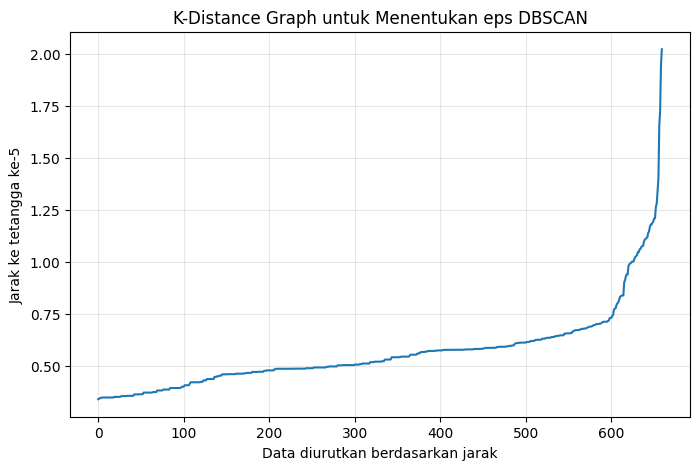

In [7]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_distances)
plt.xlabel('Data diurutkan berdasarkan jarak')
plt.ylabel(f'Jarak ke tetangga ke-{min_samples}')
plt.title('K-Distance Graph untuk Menentukan eps DBSCAN')
plt.grid(alpha=0.3)
plt.show()

,eps,Jumlah Cluster,Jumlah Noise,Silhouette Score,DBI
0,0.5,24,205,0.0270,1.4335
1,0.6,8,82,-0.0020,2.2662
2,0.7,1,58,NaN,NaN
3,0.8,2,44,0.5445,0.5154
4,0.9,3,27,0.4940,0.8784
5,1.0,2,18,0.5680,0.6015
6,1.1,2,6,0.5712,0.6251
7,1.2,2,4,0.5723,0.6288
8,1.3,2,2,0.5721,0.6349
9,1.4,2,1,0.5715,0.6354


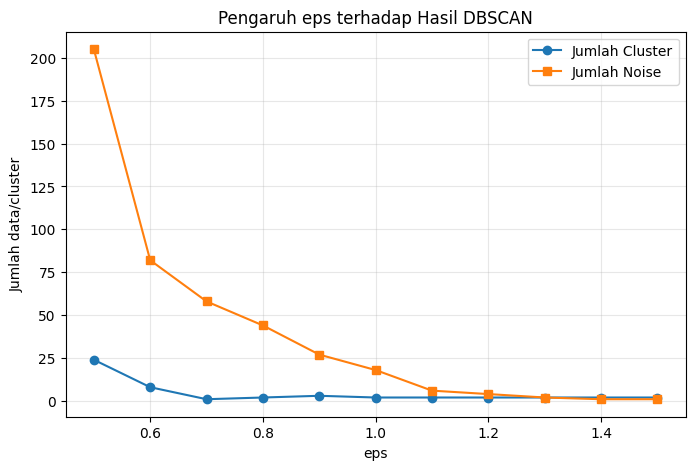

In [8]:
eps_values = np.arange(0.5, 1.51, 0.1)
rows = []

for eps in eps_values:
    labels = DBSCAN(eps=float(eps), min_samples=min_samples).fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int(np.sum(labels == -1))
    mask = labels != -1
    if n_clusters >= 2 and mask.sum() > n_clusters:
        sil = silhouette_score(X_scaled[mask], labels[mask])
        dbi = davies_bouldin_score(X_scaled[mask], labels[mask])
    else:
        sil, dbi = np.nan, np.nan
    rows.append({'eps': round(float(eps), 2), 'Jumlah Cluster': n_clusters,
                 'Jumlah Noise': n_noise, 'Silhouette Score': sil, 'DBI': dbi})

dbscan_results = pd.DataFrame(rows)
display(dbscan_results.round(4))

plt.figure(figsize=(8, 5))
plt.plot(dbscan_results['eps'], dbscan_results['Jumlah Cluster'], marker='o', label='Jumlah Cluster')
plt.plot(dbscan_results['eps'], dbscan_results['Jumlah Noise'], marker='s', label='Jumlah Noise')
plt.xlabel('eps')
plt.ylabel('Jumlah data/cluster')
plt.title('Pengaruh eps terhadap Hasil DBSCAN')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
# Pilihan awal yang menghasilkan 2 cluster dan hanya sedikit noise pada dataset ini
best_eps = 1.2
best_min_samples = 5

dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)
df_model['DBSCAN_Cluster'] = dbscan_labels

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print('eps:', best_eps)
print('min_samples:', best_min_samples)
print('Jumlah cluster (tanpa noise):', n_clusters)
print('Jumlah noise:', n_noise)
print('Jumlah anggota tiap label (-1 = noise):')
display(pd.Series(dbscan_labels).value_counts().sort_index().rename('Jumlah Data').to_frame())

mask = dbscan_labels != -1
labels_non_noise = dbscan_labels[mask]
if len(set(labels_non_noise)) >= 2:
    sil = silhouette_score(X_scaled[mask], labels_non_noise)
    dbi = davies_bouldin_score(X_scaled[mask], labels_non_noise)
    print(f'Silhouette Score (tanpa noise): {sil:.4f}')
    print(f'Davies-Bouldin Index / DBI (tanpa noise): {dbi:.4f}')
else:
    print('Metrik tidak dapat dihitung karena kurang dari 2 cluster non-noise.')

eps: 1.2
min_samples: 5
Jumlah cluster (tanpa noise): 2
Jumlah noise: 4
Jumlah anggota tiap label (-1 = noise):


,Jumlah Data
-1,4
0,608
1,48


Silhouette Score (tanpa noise): 0.5723
Davies-Bouldin Index / DBI (tanpa noise): 0.6288


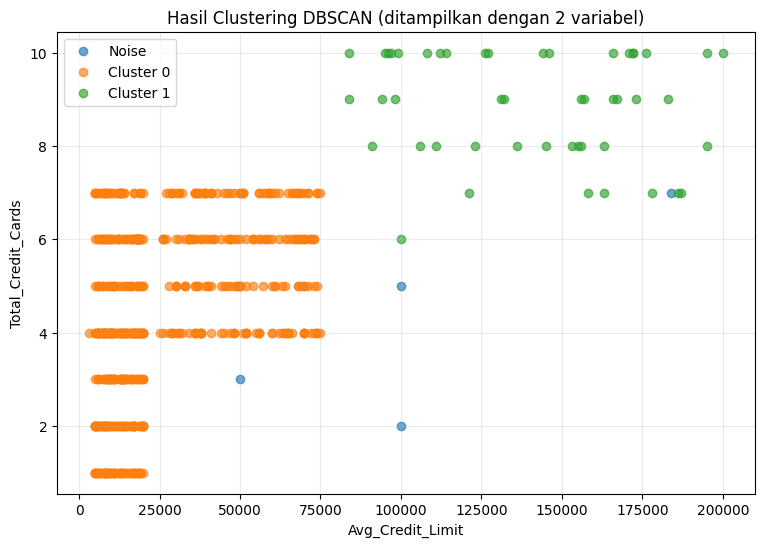

In [10]:
plt.figure(figsize=(9, 6))
for cluster in sorted(df_model['DBSCAN_Cluster'].unique()):
    subset = df_model[df_model['DBSCAN_Cluster'] == cluster]
    label = 'Noise' if cluster == -1 else f'Cluster {cluster}'
    plt.scatter(subset[x_col], subset[y_col], alpha=0.65, label=label)
plt.xlabel(x_col)
plt.ylabel(y_col)
plt.title('Hasil Clustering DBSCAN (ditampilkan dengan 2 variabel)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()